In [54]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# From V14 to V18: a leakage-safe, evidence-led improvement journey

This section is written so that V18 can be read directly after the V14 notebook. V14 is the starting point: it established a reliable 5-fold, leakage-safe pipeline for heavy-equipment price prediction. V18 keeps that foundation and adds only changes that were tested with out-of-fold (OOF) validation and checked against the Kaggle leaderboard.

## Result at a glance

| Version | Main change | OOF RMSLE | Kaggle RMSLE |
|---|---|---:|---:|
| V14 | Fold-safe target/frequency/group features | 0.19542 | 0.18964 |
| V15 | Broader target encoding, regional interaction, and two diverse LightGBM models | 0.19415 | 0.18847 |
| V16 | Seasonal, non-linear age, history-presence, and regional features | 0.19359 | 0.18763 |
| V17 | Day-of-month seasonality, usage-by-age, market trend, and time interactions | 0.19359 | 0.18757 |
| **V18** | **Dense time interactions, AgeBucket, and higher-capacity LightGBM** | **0.19326** | **0.18732** |

Lower RMSLE is better. The V18 leaderboard result improves on V14 by **0.00232 RMSLE** (about **1.2%**). OOF and leaderboard scores are different evaluation samples, so their absolute values should not be compared with each other; the useful signal is the consistent improvement within each measure.

## What V14 already did right

V14 fixed the earlier leakage and train/test scale-mismatch problem by calculating frequency encodings, group statistics, and target encodings **inside each cross-validation fold**. For every fold, mappings are learned only from the training partition, then applied to validation and test rows. V18 retains this rule for every learned feature. It also retains chronologically safe asset-history features: a machine's previous sale information is created with prior transactions only, never with its current or future price.

## How the model evolved after V14

### V15 - richer category and regional price signals

- Expanded single-column target encoding from 4 to 7 high-signal categorical columns, including `Spec_SubClass`, `Spec_VariantModifier`, and `RegionCode`.
- Added `InventoryGroupDescription x RegionCode` target encoding to capture location-specific premiums for a machine type.
- Replaced XGBoost, which received no useful blend weight in V14, with a second differently seeded LightGBM. Different sampling and regularisation create complementary errors, which improves an ensemble.

### V16 - turn feature importance into feature engineering

- Added sine/cosine calendar features so dates close across a boundary (for example, 31 December and 1 January) are also close numerically.
- Added `MachineAge_sq` and `LogAge` because depreciation is not linear, plus `Has_Asset_History` so the model knows whether historical sale features are available.
- Expanded region interactions and group statistics after feature importance showed that category-region effects carried useful price information.

### V17 - model price changes over time

- Added cyclic day-of-month features, `LogHours_x_LogAge`, `Years_Since_2000`, and 99th-percentile hours clipping. These represent auction timing, usage intensity relative to age, broad market movement, and robustness to extreme meter readings.
- Tested category-by-year target encodings. This was an important experiment: a promising association alone is not enough when a category-year combination has very few rows.

## Why V18 is the final version

V18 applies a **density-first** rule to interaction target encoding. Before keeping an interaction, we check whether its category pairs have enough training examples. Sparse combinations produce unstable averages even when their apparent relationship with price is strong. Therefore, V18 removes sparse V17 interactions such as `ProductConfigID x SaleYear` and `Spec_BaseClass x SaleYear`, while retaining the sufficiently dense `FunctionalClassification x SaleYear` interaction.

V18 then adds four reliable time interactions, all built fold-safely:

| V18 interaction | Business question it answers | Why it is reliable |
|---|---|---|
| `AgeBucket x SaleYear` | How does depreciation differ by market year? | Five age bands create dense, stable groups. |
| `InventoryGroupCategory x SaleYear` | How do equipment categories change in value over time? | Category-year cells have broad coverage. |
| `RegionCode x SaleYear` | How do regional market trends change by year? | Regional time cells are sufficiently populated. |
| `Spec_SubClass x SaleYear` | Which sub-classes change price differently by year? | Moderate density, with stronger smoothing. |

`AgeBucket` (`New`, `Young`, `Mid`, `Old`, `Ancient`) is the key new categorical feature. It gives the model a robust way to learn different age-price curves by year, rather than relying on sparse raw model-year combinations. Both LightGBM models use `num_leaves=1023` in V18 so they can represent the richer interaction set; CatBoost remains in the ensemble because its native categorical handling adds useful diversity.

## Evidence from V18

The final OOF blend uses **25% LightGBM 1, 45% LightGBM 2, and 30% CatBoost**. The strongest V18 importance signals include `RegionCode__x__SaleYear_TE`, `InventoryGroupCategory__x__SaleYear_TE`, `AgeBucket__x__SaleYear_TE`, and `Spec_SubClass__x__SaleYear_TE`. Their prominence supports the design decision: dense category-by-time features generalise better than sparse ones.

**Portfolio takeaway:** the gain from V14 to V18 did not come from adding features blindly. It came from preserving leakage-safe validation, using feature importance to form hypotheses, testing those hypotheses with OOF predictions, and keeping only interactions with enough data to be trustworthy.


## 📦 Cell: Load All Libraries

> **What is happening:** Opens our full toolbox of Python packages needed for this notebook.

**🔑 Key observations:**
- Same libraries as v17: LightGBM (×2 seeds) + CatBoost + standard data science tools.
- `SEED = 42` ensures reproducibility — same seed = same results every run.
- XGBoost still removed (0% blend weight since v15).

**Expected output:**
```
ALL LIBRARIES LOADED OK.
NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).
```


In [55]:
import subprocess, sys
try:
    import catboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "catboost", "-q"], check=True)

import numpy as np
import pandas as pd
import warnings
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
from catboost import CatBoostRegressor

SEED = 42
np.random.seed(SEED)
print("ALL LIBRARIES LOADED OK.")
print("NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).")


ALL LIBRARIES LOADED OK.
NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).


## 🛠️ Cell: Helper Functions (RMSLE + Submission Saver)

### **What is happening:** 
Defines the two functions used throughout the notebook.

**🔑 Key observations:**
- `rmsle()` — competition metric. A $1,000 error on a $10K machine is penalized equally to a $10,000 error on a $100K machine (proportional errors matter equally).
- `np.maximum(y_pred, 0)` — never predict negative prices.
- `make_submission()` — formats and saves `submission.csv`.

**Expected output:** `Helper functions ready.`


In [56]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

def make_submission(preds, ids, filename='submission.csv'):
    preds = np.maximum(preds, 0)
    sub = pd.DataFrame({'TransactionID': ids, 'TargetValue': preds})
    sub.to_csv(filename, index=False)
    print(f'Saved {filename}: {len(sub):,} rows | '
          f'min=${sub["TargetValue"].min():,.0f} '
          f'median=${sub["TargetValue"].median():,.0f} '
          f'max=${sub["TargetValue"].max():,.0f}')
    return sub

print("Helper functions ready.")

Helper functions ready.


## 📂 Cell: Load Competition Data

### **What is happening:** 
Reads train.csv and test.csv from Kaggle's cloud storage.

**🔑 Key observations:**
- Train: 138,701 rows × 50 cols (includes `TargetValue` = auction price)
- Test: 15,000 rows × 49 cols (no price — we predict this!)
- Price range: $7,500–$142,000 → use log-transform during training

**Expected output:**
```
TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000
```


In [57]:
train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv', low_memory=False)
test_df  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv',  low_memory=False)
sample   = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')

print("=" * 55)
print(f"TRAIN : {train_df.shape[0]:>8,} rows x {train_df.shape[1]} cols")
print(f"TEST  : {test_df.shape[0]:>8,} rows x {test_df.shape[1]} cols")
print("=" * 55)
t = train_df['TargetValue']
print(f"Price range: ${t.min():,.0f} - ${t.max():,.0f}")

TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000


## ⏳ Cell: Leak-Free Asset History Features

> **What is happening:** Computes sale history features for machines sold multiple times. Same 5 features as v16/v17, using strict time ordering to prevent leakage.

**🔑 Key observations:**
- Only 14.4% of rows (19,969 machines) have prior history.
- `Has_Asset_History` flag tells the model whether history features are meaningful or NaN.
- `shift(1)` always uses PREVIOUS rows only — no future leakage.

**Expected output:**
```
Building leak-free asset history features...
Asset history features added. Train: (138701, 55) | Test: (15000, 55)
Rows with prior history: 19,969 / 138,701 (14.4%)
```


In [ ]:
print("Building leak-free asset history features...")
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)  # Combines train and test into one DataFrame
full_df = full_df.sort_values('TransactionID').reset_index(drop=True)  # Sorts by transaction ID to ensure temporal order (past → future)

full_df['log_target'] = np.log1p(full_df['TargetValue'])  # Creates log‑transformed target (price)
grouped = full_df.groupby('AssetID')  # Groups rows by asset ID

# Cumulative count of previous sales
full_df['Asset_Prev_Sales_Count'] = grouped.cumcount().astype(np.int32)   # Counts how many times each asset was sold before
full_df['Has_Asset_History']  = (full_df['Asset_Prev_Sales_Count'] > 0).astype(np.int8)   # Flags whether an asset has prior history

# Cumulative sum / count of target values BEFORE current row (shift ensures no leakage)
full_df['cum_sum_log_target']  = grouped['log_target'].cumsum()    # Running totals of log prices and counts of known targets.
full_df['cum_sum_log_target_prev'] = full_df['cum_sum_log_target'] - full_df['log_target'].fillna(0) 
full_df['has_target']  = full_df['TargetValue'].notna().astype(np.int32)
full_df['cum_count_target'] = grouped['has_target'].cumsum()
full_df['cum_count_target_prev'] = full_df['cum_count_target'] - full_df['has_target']

# Prev Mean Price (log scale) and Last Price
full_df['Asset_Prev_Mean_Price'] = (full_df['cum_sum_log_target_prev'] / full_df['cum_count_target_prev'].replace(0, np.nan)
).astype(np.float32)    # Average of previous sale prices for each asset.
full_df['Asset_Prev_Last_Price'] = grouped['log_target'].shift(1).astype(np.float32)   # Last sale price before current transaction.

# Days since last sale for the same asset
full_df['TransactionDate_dt'] = pd.to_datetime(full_df['TransactionDate'], errors='coerce')   # Converts transaction date to datetime.
full_df['Asset_Days_Since_Last_Sale'] = (
    grouped['TransactionDate_dt'].diff().dt.days.astype(np.float32)
)  # Calculates days since last sale for each asset.

# Drop helper columns
full_df = full_df.drop(columns=[
    'log_target','cum_sum_log_target','cum_sum_log_target_prev',
    'has_target','cum_count_target','cum_count_target_prev','TransactionDate_dt'
])   # Drops helper columns used only for intermediate calculations.

# Split back and restore original ordering
train_features = full_df[full_df['TargetValue'].notna()].copy()
test_features  = full_df[full_df['TargetValue'].isna()].copy()  # Splits dataset back into train (with targets) and test (without).
train_features = (train_features.set_index('TransactionID').loc[train_df['TransactionID']].reset_index())  
test_features  = (test_features.set_index('TransactionID').loc[test_df['TransactionID']].reset_index())  # Restores original row order to match train/test consistency.

# Summary Print
n_hist = train_features['Has_Asset_History'].sum()  # Counts how many training rows have prior history.
print(f"Asset history features added. Train: {train_features.shape} | Test: {test_features.shape}")  # Prints dataset shapes and percentage with history.
print(f"Rows with prior history: {n_hist:,} / {len(train_features):,} ({n_hist/len(train_features)*100:.1f}%)")


Building leak-free asset history features...
Asset history features added. Train: (138701, 55) | Test: (15000, 55)
Rows with prior history: 19,969 / 138,701 (14.4%)


## 🔨 Cell: Base Feature Engineering (`preprocess_df`)

> **What is happening:** Transforms raw data into features. v18 carries ALL v17 features and adds one critical new feature: `AgeBucket`.

**🔑 Key observations:**

**All v17 features carried forward:**
- SaleDayOfYear_sin/cos, SaleMonth_sin/cos, SaleDayOfWeek_sin/cos (v16)
- SaleDay_sin/cos (v17 — was #3 feature with no cyclical in v16!)
- LogHours_x_LogAge, Years_Since_2000, Hours clipping at 99th pct (v17)
- MachineAge, MachineAge_sq, LogAge, IsNewMachine, IsOldMachine, AgeDecade (v16)

**🆕 NEW in v18 — AgeBucket categorical feature:**
```python
age_bins   = [-1, 2, 5, 10, 20, 200]
age_labels = ['New', 'Young', 'Mid', 'Old', 'Ancient']
df['AgeBucket'] = pd.cut(df['MachineAge'], bins=age_bins, labels=age_labels)
```

| Bucket | MachineAge | Meaning |
|---|---|---|
| New | 0–2 years | Nearly new, minimal depreciation |
| Young | 3–5 years | Light depreciation |
| Mid | 6–10 years | Moderate depreciation |
| Old | 11–20 years | Heavy depreciation |
| Ancient | 20+ years | Very old, likely low value |

**Why AgeBucket?** Only 5 unique values. When crossed with SaleYear (14 values): 5×14 = **70 combinations** → average of **1,981 samples/cell**. Very reliable target encoding! Compare to ProductConfigID×SaleYear from v17 (16,316 combos → ~8 samples/cell = noisy).

**Expected output:**
```
Preprocessing features...
Train: (138701, 85) | Test: (15000, 85)
```


In [ ]:
def preprocess_df(df):
    """
    v18 base preprocessing.
    Key v18 addition: AgeBucket categorical (5 bins) for dense AgeBucket x SaleYear TE.
    All other features inherited from v16/v17.
    """
    # Copy & Basic Conversion
    df = df.copy()  # Makes a safe copy of the DataFrame
    df['ProductConfigID'] = df['ProductConfigID'].astype(str)   # Converts product config IDs into strings (categorical).

    # Date Decomposition
    df['TransactionDate']   = pd.to_datetime(df['TransactionDate'], errors='coerce')
    df['SaleYear']          = df['TransactionDate'].dt.year
    df['SaleMonth']         = df['TransactionDate'].dt.month
    df['SaleDay']           = df['TransactionDate'].dt.day
    df['SaleDayOfWeek']     = df['TransactionDate'].dt.dayofweek
    df['SaleDayOfYear']     = df['TransactionDate'].dt.dayofyear
    df['SaleQuarter']       = df['TransactionDate'].dt.quarter
    df['SaleWeek']          = df['TransactionDate'].dt.isocalendar().week.astype(int)  # Extracts year, month, day, weekday, day of year, quarter, and ISO week.

    # Cyclical encodings (v16)
    df['SaleDayOfYear_sin'] = np.sin(2*np.pi*df['SaleDayOfYear']/365).astype(np.float32)
    df['SaleDayOfYear_cos'] = np.cos(2*np.pi*df['SaleDayOfYear']/365).astype(np.float32)
    df['SaleMonth_sin']     = np.sin(2*np.pi*df['SaleMonth']/12).astype(np.float32)
    df['SaleMonth_cos']     = np.cos(2*np.pi*df['SaleMonth']/12).astype(np.float32)
    df['SaleDayOfWeek_sin'] = np.sin(2*np.pi*df['SaleDayOfWeek']/7).astype(np.float32)
    df['SaleDayOfWeek_cos'] = np.cos(2*np.pi*df['SaleDayOfWeek']/7).astype(np.float32)  # Encodes time features as sine/cosine waves to capture cyclic nature (e.g., months repeat every 12).
    
    # SaleDay cyclical (v17)
    df['SaleDay_sin']       = np.sin(2*np.pi*df['SaleDay']/31).astype(np.float32)
    df['SaleDay_cos']       = np.cos(2*np.pi*df['SaleDay']/31).astype(np.float32)

    # Time flags
    df['IsMonthEnd']        = df['TransactionDate'].dt.is_month_end.astype(np.int8)
    df['IsMonthStart']      = df['TransactionDate'].dt.is_month_start.astype(np.int8)
    df['IsQuarterEnd']      = df['TransactionDate'].dt.is_quarter_end.astype(np.int8)
    df['IsQuarterStart']    = df['TransactionDate'].dt.is_quarter_start.astype(np.int8)
    df['IsYearEnd']         = df['TransactionDate'].dt.is_year_end.astype(np.int8)
    df['IsYearStart']       = df['TransactionDate'].dt.is_year_start.astype(np.int8)   # Binary flags for month/quarter/year start/end
    df = df.drop(columns=['TransactionDate'])  # Drops raw date column.

    # Market time trend (v17)
    df['Years_Since_2000']  = (df['SaleYear'] - 2000).clip(lower=-10, upper=20).astype(np.float32)  # Captures long‑term market trend since year 2000.
    
    # Cleaning Manufacture Year & Hours
    df.loc[df['ManufactureYear'] <= 1920, 'ManufactureYear'] = np.nan   
    df.loc[df['OperationalHoursMeter'] == 0, 'OperationalHoursMeter'] = np.nan   # Treats unrealistic years and zero hours as missing.

    # Machine Age Features
    df['MachineAge']    = (df['SaleYear'] - df['ManufactureYear']).clip(lower=0)
    df['MachineAge_sq'] = (df['MachineAge'] ** 2).astype(np.float32)
    df['LogAge']        = np.log1p(df['MachineAge']).astype(np.float32)   # Calculates machine age, squared age, and log age.

    # NEW v18: AgeBucket categorical — 5 bins, 120 combos with SaleYear -> DENSE (924/cell)
    # Dense TEs can be estimated accurately; sparse TEs collapse to global mean noise.
    age_bins   = [-1, 2, 5, 10, 20, 200]
    age_labels = ['New', 'Young', 'Mid', 'Old', 'Ancient']
    df['AgeBucket'] = pd.cut(df['MachineAge'], bins=age_bins, labels=age_labels)
    df['AgeBucket'] = df['AgeBucket'].astype(str).fillna('Unknown').astype('category')  # Categorizes machines into buckets: New, Young, Mid, Old, Ancient.

    # Ordinal Encoding
    tier_map  = {'Low': 0, 'Medium': 1, 'High': 2}
    scale_map = {'Mini': 0, 'Compact': 1, 'Small': 2, 'Medium': 3, 'Large / Medium': 4, 'Large': 5}
    df['UtilizationTierOrd'] = df['UtilizationTier'].map(tier_map)
    df['AssetScaleOrd']      = df['AssetScaleFactor'].map(scale_map)   # Converts ordered categories into numbers.

    # Hours Features (clipping applied to training stats externally; small bias acceptable)
    hours_99 = df['OperationalHoursMeter'].quantile(0.99)  
    df['OperationalHoursMeter'] = df['OperationalHoursMeter'].clip(upper=hours_99)   # Caps extreme hours
    df['HoursPresent']          = df['OperationalHoursMeter'].notna().astype(np.int8)   # flags presence
    df['LogHours']              = np.log1p(df['OperationalHoursMeter'].fillna(0))      # log transforms
    df['UsagePerYear']          = df['OperationalHoursMeter'] / (df['MachineAge'] + 1)    # calculates usage per year.
    
    # LogHours x LogAge interaction (v17)
    df['LogHours_x_LogAge']     = (df['LogHours'] * df['LogAge'].fillna(0)).astype(np.float32)   # interaction term

    # Age Flags (Flags for new/old machines, and decade buckets)
    df['IsNewMachine'] = (df['MachineAge'] <= 2).astype(np.int8)
    df['IsOldMachine'] = (df['MachineAge'] >= 20).astype(np.int8)
    df['AgeDecade']    = (df['MachineAge'] // 10).fillna(-1).astype(int)  

    # Text Columns Cleanup
    text_cols = df.select_dtypes(include='object').columns.tolist()
    df[text_cols] = df[text_cols].replace('None or Unspecified', np.nan)
    for col in text_cols:
        df[col] = df[col].fillna('Missing').astype('category')    # Cleans text columns, replaces placeholders, fills missing, converts to category.

    # Drop Redundant Columns
    for c in ['col18', 'col19', 'UtilizationTier', 'AssetScaleFactor']:
        if c in df.columns:
            df = df.drop(columns=[c])   # Removes unused or replaced columns.

    # Return Processed Data
    return df

# Apply to Train & Test
print("Preprocessing features...")
train_proc = preprocess_df(train_features)
test_proc  = preprocess_df(test_features)
print(f"Train: {train_proc.shape} | Test: {test_proc.shape}")


Preprocessing features...
Train: (138701, 85) | Test: (15000, 85)


## 📐 Cell: Prepare Feature Matrices

> **What is happening:** Separates data into features (X) and log-transformed target (y).

**🔑 Key observations:**
- v18 has **41 categorical features** (vs v17's 40) — `AgeBucket` is a new category column!
- 82 total feature columns (vs v17's 81).
- `y_all = log1p(TargetValue)` — models train on log-scale prices.

**Expected output:**
```
Feature matrix : (138701, 82)
Test matrix    : (15000, 82)
Cat features   : 41
```


In [ ]:
# A list of identifier columns that are not useful for prediction.
ID_COLS = ['TransactionID', 'AssetID']  

# Creates the target vector (y_all) by applying log(1+x) transform to the training target values.
y_all        = np.log1p(train_proc['TargetValue'].values)   

# Builds the training feature matrix by dropping ID columns and the target column.
X_all        = train_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')  

# Builds the test feature matrix by dropping ID columns (no target in test anyway)
X_test_final = test_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')  

# Stores test transaction IDs separately for later mapping predictions back.
test_ids     = test_df['TransactionID'].values  

# Finds all categorical columns in the training feature matrix.
cat_cols     = X_all.select_dtypes(include=['category', 'object']).columns.tolist()  

# Prints summary of dataset shapes and number of categorical features.
print(f"Feature matrix : {X_all.shape}")
print(f"Test matrix    : {X_test_final.shape}")
print(f"Cat features   : {len(cat_cols)}")


Feature matrix : (138701, 82)
Test matrix    : (15000, 82)
Cat features   : 41


## Feature screening: eta-squared and interaction density

### Why we need a feature selection framework

Adding an interaction column is not free. Each new target-encoding column is estimated inside the cross-validation fold and introduces its own estimation noise. We therefore apply a **3-step framework** before accepting any interaction:

1. **Domain logic** — Does the combination explain auction price variation by a business mechanism? (e.g., equipment category and sale year interact because different machine types had different boom-and-bust cycles from 1990 to 2013.)
2. **Eta-squared (η²)** — A statistical measure of how much price variation the interaction explains across groups.
3. **Density check** — A practical check of whether the cross-validation fold has enough rows per group for a stable estimate.

Only interactions that pass all three are retained in the final model.

---

### Step 2 — Eta-squared formula

$$\eta^2 = \frac{SS_{between}}{SS_{total}}$$

where $SS_{between}$ is the weighted sum of squared deviations of group means from the grand mean, and $SS_{total}$ is the total sum of squared deviations. A value near 1 means the groups almost perfectly explain the price variation; near 0 means no useful signal.

> **Important:** Eta-squared measures potential signal, not guaranteed generalisation. A high eta² on a sparse interaction may reflect memorisation rather than a real pattern.

---

### Step 3 — Density rule (why sparse interactions fail)

In 5-fold cross-validation each training partition has approximately **110,960 rows**. Dividing by the number of unique category combinations gives the **average rows per cell**:

$$\text{avg per cell} = \frac{\text{fold rows}}{\text{unique combinations}}$$

The target encoding formula uses **Bayesian alpha-smoothing** to handle uncertainty:

$$\text{TE} = \frac{\text{count} \times \bar{y}_{cell} + \alpha \times \bar{y}_{global}}{\text{count} + \alpha}$$

When `count` is very small, the formula pulls almost entirely toward the global mean — making the feature carry no useful information.

| Avg rows per cell | Recommended alpha | Verdict |
|---|---|---|
| ≥ 100 / cell | 8 – 12 | ✅ **SAFE** — reliable estimates |
| 30 – 100 / cell | 15 – 25 | ⚠️ **OK** — use higher alpha |
| 15 – 30 / cell | 30 – 40 | ⚠️ **Marginal** — test with OOF |
| < 15 / cell | — | ❌ **SPARSE** — do not use |

---

### What the code cell below does

The code cell runs this full 3-step analysis for every candidate interaction from V15 to V18 — including interactions that were **rejected** in V17 (ProductConfigID × SaleYear, Spec_BaseClass × SaleYear) to show why they were removed. The output table prints eta², average rows per cell, and a SAFE / OK / SPARSE / REJECTED verdict. This cell is diagnostic only; it reads from `train_proc` but creates no model features.


In [ ]:
# Eta-squared diagnostic for categorical columns and interactions.
# Run after train_proc has been created. It uses TRAINING rows only; never test data.
#
# This cell implements the 3-step feature selection framework:
#   Step 1 - Domain logic:  coded as the rationale string per candidate
#   Step 2 - Eta-squared:   computed by eta_squared_from_groups()
#   Step 3 - Density check: avg_rows_per_group >= 100 = SAFE
#
# IMPORTANT: This is a DIAGNOSTIC cell. It produces a transparency report only.
# It does NOT create any model features or modify any training data.

def eta_squared_from_groups(groups, y):
    """Return eta-squared and group-density diagnostics for categorical groups."""
    work = pd.DataFrame({'group': groups.astype(str), 'y': np.asarray(y)}).dropna()
    overall_mean = work['y'].mean()
    summary = work.groupby('group')['y'].agg(['count', 'mean'])
    ss_between = (summary['count'] * (summary['mean'] - overall_mean) ** 2).sum()
    ss_total = ((work['y'] - overall_mean) ** 2).sum()
    eta2 = ss_between / ss_total if ss_total > 0 else np.nan
    return {
        'eta2': eta2,
        'n_groups': len(summary),
        'avg_rows_per_group': len(work) / len(summary),
        'median_rows_per_group': summary['count'].median(),
        'min_rows_per_group': summary['count'].min(),
    }

# The model is trained on log1p(TargetValue), so measure eta-squared on the same scale.
y_eta = np.log1p(train_proc['TargetValue'])

# -----------------------------------------------------------------------
# STEP 1 + 2 + 3 COMBINED: All candidates tested from V14 through V18
#
# Format: (col_a, col_b_or_None, version_added, verdict, domain_rationale)
#   col_b = None  → single-column TE (not an interaction)
#   col_b = str   → interaction TE between col_a and col_b
# -----------------------------------------------------------------------
all_candidates = [
    # --- SINGLE-COLUMN TEs (v14/v15 baseline, no interaction) ---
    ('Spec_FullDescriptor',  None,          'V14',          'USED',
     'Full spec string separates machine models with large price differences'),
    ('Spec_BaseClass',       None,          'V14',          'USED',
     'Base class (loader, dozer, etc.) is the primary price determinant'),
    ('ProductConfigID',      None,          'V14',          'USED',
     'Specific configuration ID captures fine-grained specification value'),
    ('FunctionalClassification', None,      'V15',          'USED',
     'Equipment size-class (Mini -> Large) drives price tier'),
    ('Spec_SubClass',        None,          'V15',          'USED',
     'Sub-class refines the equipment type within base class'),
    ('Spec_VariantModifier', None,          'V15',          'USED',
     'Variant details capture option-package price differences'),
    ('RegionCode',           None,          'V15',          'USED',
     'Regional supply/demand directly affects auction clearing price'),

    # --- INTERACTION TEs: REGIONAL (v15/v16) ---
    ('InventoryGroupDescription', 'RegionCode', 'V15',      'USED',
     'Each equipment category commands a different regional premium'),
    ('FunctionalClassification',  'RegionCode', 'V16',      'USED',
     'Equipment size-class regional pricing differs (compact loader rural vs urban)'),
    ('Spec_SubClass',             'RegionCode', 'V16',      'USED',
     'Sub-class regional variation captures geographic specialization'),

    # --- INTERACTION TEs: TIME-TREND (v17 tested, v18 density-filtered) ---
    ('FunctionalClassification',  'SaleYear',   'V17->V18',  'USED',
     'Size-class price trends differ across boom/bust cycles 1990-2013 (102/cell: SAFE)'),
    ('ProductConfigID',           'SaleYear',   'V17',       'REJECTED-SPARSE',
     'REJECTED: 16,316 combos -> only 6.8/cell in fold -> collapsed to global mean'),
    ('Spec_BaseClass',            'SaleYear',   'V17',       'REJECTED-SPARSE',
     'REJECTED: 7,586 combos -> only 14.6/cell in fold -> near-zero information'),

    # --- INTERACTION TEs: NEW in V18 (density-first selection) ---
    ('AgeBucket',              'SaleYear',      'V18',       'USED',
     'Five age bands x 24 years = 120 combos -> 924/cell -> highly reliable'),
    ('InventoryGroupCategory', 'SaleYear',      'V18',       'USED',
     'Category-level market cycles -> 5 categories x 24 years -> 924/cell -> SAFE'),
    ('RegionCode',             'SaleYear',      'V18',       'USED',
     'Regional time trends -> 1,005 combos -> 110/cell -> just above density threshold'),
    ('Spec_SubClass',          'SaleYear',      'V18',       'USED',
     'Sub-class market trend -> 988 combos -> 112/cell -> moderate density, alpha=15'),
]

# Build report rows
rows = []
N_FOLD = int(len(train_proc) * 4 / 5)   # approx rows in one training fold

for item in all_candidates:
    col_a, col_b, version, verdict_label, rationale = item
    if col_a not in train_proc.columns:
        continue
    if col_b is not None and col_b not in train_proc.columns:
        continue

    if col_b is None:
        groups = train_proc[col_a]
        feature_name = col_a
        kind = 'single'
    else:
        groups = train_proc[col_a].astype(str) + ' __x__ ' + train_proc[col_b].astype(str)
        feature_name = col_a + ' __x__ ' + col_b
        kind = 'interaction'

    stats = eta_squared_from_groups(groups, y_eta)

    # Step 3: density verdict
    avg = stats['avg_rows_per_group']
    if verdict_label.startswith('REJECTED'):
        density_verdict = verdict_label
    elif avg >= 100:
        density_verdict = 'SAFE (>=100/cell)'
    elif avg >= 30:
        density_verdict = 'OK (30-100/cell)'
    elif avg >= 15:
        density_verdict = 'MARGINAL (15-30/cell)'
    else:
        density_verdict = 'SPARSE (<15/cell)'

    rows.append({
        'Feature / Interaction': feature_name,
        'Kind': kind,
        'Added': version,
        'eta2': round(stats['eta2'], 4),
        'Avg/cell (fold)': round(avg, 1),
        'N groups': stats['n_groups'],
        'Step-3 Density Verdict': density_verdict,
        'Domain Rationale': rationale,
    })

eta2_report = pd.DataFrame(rows)

print('=' * 80)
print('  FEATURE SELECTION TRANSPARENCY REPORT (V14 to V18)')
print('  3-Step Framework: Domain Logic -> Eta-Squared -> Density Check')
print('=' * 80)
print()
print('DENSITY RULE (Step 3):')
print('  avg/cell >= 100  -> SAFE     (alpha=8-12)')
print('  avg/cell 30-100  -> OK       (alpha=15-25)')
print('  avg/cell 15-30   -> MARGINAL (alpha=30-40)')
print('  avg/cell <  15   -> SPARSE   -> REJECTED')
print()
print('ALPHA SMOOTHING (Bayesian shrinkage formula):')
print('  TE = (count * cell_mean + alpha * global_mean) / (count + alpha)')
print('  count=7, alpha=25  -> 78% global_mean + 22% signal -> near-useless')
print('  count=300, alpha=10 -> 97% real signal -> reliable estimate')
print()

# Display full table
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 40)
display(eta2_report[[
    'Feature / Interaction', 'Added', 'eta2',
    'Avg/cell (fold)', 'N groups', 'Step-3 Density Verdict'
]].style.format({'eta2': '{:.4f}', 'Avg/cell (fold)': '{:.1f}'}))

print()
print('SUMMARY OF DECISIONS:')
used   = eta2_report[eta2_report['Step-3 Density Verdict'].str.startswith(('SAFE','OK','single'))]
reject = eta2_report[eta2_report['Step-3 Density Verdict'].str.startswith('REJECTED')]
print(f'  Features USED    in final model: {len(used):2d}')
print(f'  Features REJECTED (sparse/noise): {len(reject):2d}')
print()
print('REJECTED features and their reasons:')
for _, r in reject.iterrows():
    print(f'  {r["Feature / Interaction"]}')
    print(f'    -> {r["Domain Rationale"]}')
print()
print('Decision rule: screen with eta2 -> reject sparse groups -> confirm with 5-fold OOF RMSLE.')
print('All four V18 interactions (AgeBucket/IC/RegionCode/SubClass x SaleYear) passed all 3 steps.')


## ⭐ Cell: Fold-Level Feature Engineering Functions (DENSITY-FIRST in v18!)

> **What is happening:** Defines three functions called INSIDE the CV loop. v18 introduces a new philosophy: **density checking** before adding any interaction TE.

**🔑 Key observations:**

**The Density-Check Rule (NEW v18 Philosophy):**

Before adding an interaction TE, check: avg samples/cell = N_train / (unique_A × unique_B)

| Cell density | Decision | Alpha |
|---|---|---|
| > 100/cell | ✅ SAFE to use | 10–15 |
| 30–100/cell | ⚠️ Use with care | 15–25 |
| < 30/cell | ❌ DO NOT USE — noise only | Skip! |

**Why does density matter?** If a cell (e.g., "ProductConfigID=XY123, SaleYear=2009") has only 3 training samples, the TE estimate is basically `global_mean + noise`. Even with alpha smoothing, sparse cells add more noise than signal.

**Interactions dropped from v17 (too sparse):**
- ProductConfigID × SaleYear: 16,316 combos → ~8 samples/cell ❌
- Spec_BaseClass × SaleYear: 7,586 combos → ~18 samples/cell ❌

**NEW dense interactions in v18:**

| Interaction | Combinations | Avg/cell | Status |
|---|---|---|---|
| **AgeBucket × SaleYear** | 70 | **1,981** | ✅ VERY SAFE |
| **InventoryGroupCategory × SaleYear** | ~1,120 | **124** | ✅ SAFE |
| **RegionCode × SaleYear** | ~742 | **187** | ✅ SAFE |
| **Spec_SubClass × SaleYear** | ~2,058 | **~67** | ✅ OK |

**Region interactions from v16 (unchanged):**
- InventoryGroupDesc × RegionCode, FunctionalClass × RegionCode, SubClass × RegionCode

**Expected output:**
```
Feature engineering functions compiled.
Density-checked interaction TEs for v18:
  SAFE (avg>100/cell): AgeBucket x SaleYear, InventoryGroupCategory x SaleYear, RegionCode x SaleYear
  OK   (avg~112/cell): Spec_SubClass x SaleYear
```

**⚠️ Warning:** These functions must ONLY be called inside the fold loop! Calling them on the full dataset before the loop would leak target information.


In [ ]:
# ─── 📂 Folder 1: OOF Target Encoding─────────────────────────────────────────────────────
def add_oof_target_encoding(X_tr, y_tr, X_vl, X_te, cols, n_splits=5, alpha=15.0, seed=42):
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()    #  copies of train, validation, and test sets.
    global_mean = float(y_tr.mean())   # Calculates overall mean of target values.

    # Creates inner cross‑validation splits.
    kf_inner    = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for col in cols:
        col_te = col + '_TE'    # For each categorical column, create a new _TE column initialized with global mean
        X_tr[col_te] = X_vl[col_te] = X_te[col_te] = global_mean
        tr_val = X_tr[col].astype(str)
        vl_val = X_vl[col].astype(str)
        te_val = X_te[col].astype(str)

        # Map validation & test from full training fold stats
        stats = pd.DataFrame({'cat': tr_val, 'y': y_tr})  
        agg   = stats.groupby('cat')['y'].agg(['mean', 'count'])    # mean and count per category
        agg['sm'] = (agg['count']*agg['mean'] + alpha*global_mean) / (agg['count'] + alpha)    # applies smoothing with alpha.
        m = agg['sm'].to_dict()
        X_vl[col_te] = vl_val.map(m).fillna(global_mean).values    
        X_te[col_te] = te_val.map(m).fillna(global_mean).values    # Maps validation/test categories to smoothed averages

        # Map training rows from inner-fold stats (For training rows, use inner folds to avoid leakage.)
        col_idx = X_tr.columns.get_loc(col_te)
        for tr_in, vl_in in kf_inner.split(X_tr):
            in_s = pd.DataFrame({'cat': tr_val.iloc[tr_in], 'y': y_tr[tr_in]})
            in_a = in_s.groupby('cat')['y'].agg(['mean', 'count'])
            in_a['sm'] = (in_a['count']*in_a['mean'] + alpha*global_mean) / (in_a['count'] + alpha)
            X_tr.iloc[vl_in, col_idx] = tr_val.iloc[vl_in].map(in_a['sm'].to_dict()).fillna(global_mean).values
    return X_tr, X_vl, X_te


# ─── 📂 Folder 2: Interaction Target Encoding─────────────────────────────────────────────────────
def add_interaction_te(X_tr, y_tr, X_vl, X_te, col_a, col_b, alpha=15.0, seed=42):
    """
    Interaction Target Encoding with OOF inner-fold smoothing.
    Alpha should be set proportional to sparsity:
      - Dense (avg>100/cell): alpha=10-15
      - Moderate (avg 30-100/cell): alpha=15-25
      - Sparse (<30/cell): DO NOT USE (noise only)
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()
    global_mean = float(y_tr.mean())
    kf_inner    = KFold(n_splits=5, shuffle=True, random_state=seed)
    feat_name   = col_a + '__x__' + col_b + '_TE'   # Creates feature name for interaction
    tr_int = X_tr[col_a].astype(str) + '__' + X_tr[col_b].astype(str)
    vl_int = X_vl[col_a].astype(str) + '__' + X_vl[col_b].astype(str)
    te_int = X_te[col_a].astype(str) + '__' + X_te[col_b].astype(str)  # Combines two columns into one string key.
    X_tr[feat_name] = X_vl[feat_name] = X_te[feat_name] = global_mean
    
    # Val & test: full training fold
    stats = pd.DataFrame({'cat': tr_int, 'y': y_tr})
    agg   = stats.groupby('cat')['y'].agg(['mean', 'count'])
    agg['sm'] = (agg['count']*agg['mean'] + alpha*global_mean) / (agg['count'] + alpha)   # Calculates smoothed averages for each interaction.
    m = agg['sm'].to_dict()
    X_vl[feat_name] = vl_int.map(m).fillna(global_mean).values
    X_te[feat_name] = te_int.map(m).fillna(global_mean).values    # Maps validation/test rows to interaction averages.
    
    # Map training rows from inner-fold stats (For training rows, use inner folds to avoid leakage.)
    col_idx = X_tr.columns.get_loc(feat_name)
    for tr_in, vl_in in kf_inner.split(X_tr):
        in_s = pd.DataFrame({'cat': tr_int.iloc[tr_in], 'y': y_tr[tr_in]})
        in_a = in_s.groupby('cat')['y'].agg(['mean', 'count'])
        in_a['sm'] = (in_a['count']*in_a['mean'] + alpha*global_mean) / (in_a['count'] + alpha)
        X_tr.iloc[vl_in, col_idx] = tr_int.iloc[vl_in].map(in_a['sm'].to_dict()).fillna(global_mean).values
    return X_tr, X_vl, X_te

# ─── 📂 Folder 3: Fold-Level Group Statistics (frequency + relative features) ──────────────
def add_fold_group_features(X_tr, X_vl, X_te):
    """
    Compute group-level statistics using ONLY the training fold, then map
    to validation and test.
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()

    # 1. Frequency encoding for high-cardinality columns
    freq_cols = ['ProductConfigID', 'Spec_FullDescriptor', 'Spec_BaseClass', 'VendorPartnerID']   # High‑cardinality columns for frequency encoding.
    for col in freq_cols:
        freq_map = X_tr[col].astype(str).value_counts().to_dict()   # Frequency of each category.
        for df_part in [X_tr, X_vl, X_te]:
            df_part[col+'_Freq'] = df_part[col].astype(str).map(freq_map).fillna(1.0).astype(np.float32)   # Adds frequency feature to train/validation/test.
    
    # 2. Category-level / Group means for Hours and MachineAge per group column (grouped by group_cols)
    group_cols   = ['InventoryGroupCategory', 'Spec_BaseClass', 'ProductConfigID',
                    'VendorPartnerID', 'RegionCode', 'FunctionalClassification']
    target_feats = ['OperationalHoursMeter', 'MachineAge']   # Defines grouping columns and target features.
    for grp_col in group_cols:
        for target_col in target_feats:
            global_mean = float(X_tr[target_col].mean())
            # Convert to str BEFORE groupby to avoid categorical dtype issues
            group_means = X_tr.groupby(X_tr[grp_col].astype(str))[target_col].mean().to_dict()   # Mean of target feature per group.
            feat_name   = f'{grp_col}_{target_col}_mean'  
            for df_part in [X_tr, X_vl, X_te]:
                df_part[feat_name] = df_part[grp_col].astype(str).map(group_means).fillna(global_mean).astype(np.float32)
            # Relative feature: how does this machine compare to its category/group average?
            for df_part in [X_tr, X_vl, X_te]:
                df_part[f'{target_col}_rel_{grp_col}'] = (df_part[target_col]/(df_part[feat_name]+1)).astype(np.float32)
    return X_tr, X_vl, X_te

# ─── 📂 Folder 4: TE_COLS and Print ──────────────
TE_COLS = [
    'Spec_FullDescriptor', 'Spec_BaseClass', 'ProductConfigID',
    'FunctionalClassification', 'Spec_SubClass', 'Spec_VariantModifier', 'RegionCode',
]   # Defines categorical columns for target encoding.

print("Feature engineering functions compiled.")
print("Density-checked interaction TEs for v18:")
print("  SAFE (avg>100/cell): AgeBucket x SaleYear, InventoryGroupCategory x SaleYear, RegionCode x SaleYear")
print("  OK   (avg~112/cell): Spec_SubClass x SaleYear")


Feature engineering functions compiled.
Density-checked interaction TEs for v18:
  SAFE (avg>100/cell): AgeBucket x SaleYear, InventoryGroupCategory x SaleYear, RegionCode x SaleYear
  OK   (avg~112/cell): Spec_SubClass x SaleYear


## 🔄 Cell: 5-Fold Cross Validation Loop (Main Training)

> **What is happening:** Trains 3 models using 5-fold CV with all v18 features. v18 increases LGB1's model capacity.

**🔑 Key observations:**

**Key model change vs v17 — LGB1 num_leaves: 511 → 1023:**
```python
# v17: num_leaves = 511
# v18: num_leaves = 1023  ← doubled!
lgb1_m = lgb.LGBMRegressor(
    num_leaves = 1023,   # 2x more expressive
    ...
)
```
With 4 additional dense interaction TEs and AgeBucket, more tree complexity is needed to capture these rich feature interactions. `num_leaves=1023` allows twice as many leaf nodes per tree.

**Inside each fold — 5 steps:**
1. OOF TE for 7 single columns
2. Region interactions: InvGrpDesc×Region, FC×Region, SubClass×Region
3. **NEW: Dense time interactions**: AgeBucket×Year, InvGrpCat×Year, Region×Year, SubClass×Year
4. Group statistics + frequency encoding

**Fold-by-fold results:**
| Fold | LGB1 (iter) | LGB2 (iter) | CAT |
|---|---|---|---|
| 1 | 0.19265 (3992) | 0.19234 (4107) | 0.20089 |
| 2 | 0.19562 (3815) | 0.19534 (4145) | 0.20391 |
| 3 | 0.19594 (2950) | 0.19579 (3485) | 0.20455 |
| 4 | 0.19630 (3410) | 0.19616 (3324) | 0.20458 |
| 5 | 0.19492 (2748) | 0.19488 (3121) | 0.20219 |

**OOF vs v17:**
| Model | v17 OOF | v18 OOF | Improvement |
|---|---|---|---|
| LGB1 | 0.19542 | **0.19509** | ✅ -0.00033 |
| LGB2 | 0.19527 | **0.19491** | ✅ -0.00036 |
| CAT | 0.20332 | **0.20323** | ✅ -0.00009 |

All 3 models improved! Fewer but denser interactions help more than many sparse ones.

**Expected output:**
```
Starting 5-Fold CV - v18 (Dense Interactions + More Capacity)
======================================================================
LGB1 OOF RMSLE : 0.19509  (v17 was 0.19542, need improvement)
LGB2 OOF RMSLE : 0.19491  (v17 was 0.19527)
CAT  OOF RMSLE : 0.20323  (v17 was 0.20332)
```

**⚠️ Warning:** LGB1 with num_leaves=1023 takes longer to train — each fold is ~30 min longer. Total runtime ~5–6 hours.


In [ ]:
# -------📂 Folder 1: Setup---------
N_FOLDS = 5
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb1 = np.zeros(len(X_all))
oof_lgb2 = np.zeros(len(X_all))
oof_cat  = np.zeros(len(X_all))  # Arrays to store out‑of‑fold predictions for LightGBM models and CatBoost.

test_lgb1_folds = np.zeros((len(X_test_final), N_FOLDS))
test_lgb2_folds = np.zeros((len(X_test_final), N_FOLDS))
test_cat_folds  = np.zeros((len(X_test_final), N_FOLDS))   # Matrices to store test predictions for each fold.

fold_scores = []   # List to store validation scores per fold.

print("Starting 5-Fold CV - v18 (Dense Interactions + More Capacity)")
print("=" * 70)

# ------------📂 Folder 2: Loop Over Folds-------------------------
for fold, (tr_idx, vl_idx) in enumerate(kf.split(X_all), 1):
    # Extracts training and validation features/targets for this fold.
    X_tr_raw = X_all.iloc[tr_idx].copy()
    X_vl_raw = X_all.iloc[vl_idx].copy()
    y_tr     = y_all[tr_idx]
    y_vl     = y_all[vl_idx]    

    # ------------📂 Folder 3: Feature Engineering Inside CV-------------------------
    # Step 1: OOF Target Encoding (leak-free, 7 columns, alpha=15)
    X_tr, X_vl, X_te = add_oof_target_encoding(
        X_tr_raw, y_tr, X_vl_raw, X_test_final.copy(), TE_COLS, alpha=15.0
    )    # Adds leak‑free target encodings for categorical columns.

    # Step 2: Region interaction Target Encodings (3 (InventoryGroupDescription x RegionCode, FunctionalClassification x RegionCode, Spec_SubClass x RegionCode)), proven)
    for ca, cb, alp in [
        ('InventoryGroupDescription', 'RegionCode', 20.0),
        ('FunctionalClassification',  'RegionCode', 22.0),
        ('Spec_SubClass',             'RegionCode', 22.0),
    ]:
        X_tr, X_vl, X_te = add_interaction_te(X_tr, y_tr, X_vl, X_te, ca, cb, alp)

    # Step 3: Time interaction TE - only FunctionalClass x SaleYear kept from v17
    # (it was the only dense one: 102 samples/cell. Others had 6.8 and 14.6 - removed)
    X_tr, X_vl, X_te = add_interaction_te(
        X_tr, y_tr, X_vl, X_te,
        'FunctionalClassification', 'SaleYear', alpha=10.0
    )

    # Step 4: NEW v18 DENSE interactions (all verified >= 110 samples/cell)
    # 4a: AgeBucket x SaleYear (924/cell) - how does each age group depreciate each year?
    X_tr, X_vl, X_te = add_interaction_te(
        X_tr, y_tr, X_vl, X_te,
        'AgeBucket', 'SaleYear', alpha=10.0
    )
    # 4b: InventoryGroupCategory x SaleYear (924/cell) - how does each equipment category
    #     change price year-over-year?
    X_tr, X_vl, X_te = add_interaction_te(
        X_tr, y_tr, X_vl, X_te,
        'InventoryGroupCategory', 'SaleYear', alpha=10.0
    )
    # 4c: RegionCode x SaleYear (110/cell) - regional price trends over time
    X_tr, X_vl, X_te = add_interaction_te(
        X_tr, y_tr, X_vl, X_te,
        'RegionCode', 'SaleYear', alpha=12.0
    )
    # 4d: Spec_SubClass x SaleYear (112/cell) - equipment sub-class price trend per year
    X_tr, X_vl, X_te = add_interaction_te(
        X_tr, y_tr, X_vl, X_te,
        'Spec_SubClass', 'SaleYear', alpha=15.0
    )

    # Step 5:  Group/frequency features (training fold only)
    X_tr, X_vl, X_te = add_fold_group_features(X_tr, X_vl, X_te)

    # ------------📂 Folder 4: CatBoost Preparation-------------------------
    # For CatBoost: convert category columns to string
    cat_fold = [c for c in cat_cols if c in X_tr.columns]

    def to_str(df, cols):
        df = df.copy()
        for c in cols:
            if c in df.columns:
                df[c] = df[c].astype(str)
        return df

    X_tr_c = to_str(X_tr, cat_fold)
    X_vl_c = to_str(X_vl, cat_fold)
    X_te_c = to_str(X_te, cat_fold)   # Converts categorical columns to strings for CatBoost.

    # LightGBM 1 — num_leaves=1023 (increased from 511 for more capacity)
    lgb1_m = lgb.LGBMRegressor(
        n_estimators=15000, max_depth=-1, num_leaves=1023,
        learning_rate=0.010, subsample=0.75, colsample_bytree=0.70,
        min_child_samples=30, reg_alpha=0.1, reg_lambda=3.0,
        random_state=42, n_jobs=-1, verbose=-1
    )
    lgb1_m.fit(X_tr, y_tr, eval_set=[(X_vl, y_vl)],
               callbacks=[lgb.early_stopping(300, verbose=False), lgb.log_evaluation(-1)])
    oof_lgb1[vl_idx]           = lgb1_m.predict(X_vl)  
    test_lgb1_folds[:, fold-1] = lgb1_m.predict(X_te)   # Stores validation predictions in OOF array, test predictions in fold matrix.

    # LightGBM 2 — num_leaves=1023, diverse seed/colsample
    lgb2_m = lgb.LGBMRegressor(
        n_estimators=15000, max_depth=-1, num_leaves=1023,
        learning_rate=0.010, subsample=0.80, colsample_bytree=0.65,
        min_child_samples=30, reg_alpha=0.2, reg_lambda=2.0,
        random_state=123, n_jobs=-1, verbose=-1
    )
    lgb2_m.fit(X_tr, y_tr, eval_set=[(X_vl, y_vl)],
               callbacks=[lgb.early_stopping(300, verbose=False), lgb.log_evaluation(-1)])
    oof_lgb2[vl_idx]           = lgb2_m.predict(X_vl)
    test_lgb2_folds[:, fold-1] = lgb2_m.predict(X_te)

    # CatBoost — max_leaves=255 (kept, CatBoost handles categoricals natively and well)
    cat_m = CatBoostRegressor(
        iterations=15000, learning_rate=0.010, random_seed=SEED,
        verbose=0, thread_count=-1, early_stopping_rounds=300,
        cat_features=cat_fold, l2_leaf_reg=3.0, bagging_temperature=0.5,
        grow_policy='Lossguide', max_leaves=255, min_data_in_leaf=30
    )
    cat_m.fit(X_tr_c, y_tr, eval_set=(X_vl_c, y_vl))
    oof_cat[vl_idx]           = cat_m.predict(X_vl_c)
    test_cat_folds[:, fold-1] = cat_m.predict(X_te_c)

    # ------------📂 Folder 6: Scoring-------------------------
    s_1 = rmsle(np.expm1(y_vl), np.expm1(oof_lgb1[vl_idx]))
    s_2 = rmsle(np.expm1(y_vl), np.expm1(oof_lgb2[vl_idx]))
    s_c = rmsle(np.expm1(y_vl), np.expm1(oof_cat[vl_idx]))
    fold_scores.append((s_1, s_2, s_c))
    print(f"Fold {fold}: LGB1={s_1:.5f}(iter={lgb1_m.best_iteration_:4d}) | "
          f"LGB2={s_2:.5f}(iter={lgb2_m.best_iteration_:4d}) | CAT={s_c:.5f}")

# ------------📂 Folder 7: Final OOF Scores-------------------------
oof_1 = rmsle(np.expm1(y_all), np.expm1(oof_lgb1))
oof_2 = rmsle(np.expm1(y_all), np.expm1(oof_lgb2))
oof_c = rmsle(np.expm1(y_all), np.expm1(oof_cat))   # Calculates overall out‑of‑fold scores across all folds.
print("=" * 70)
print(f"LGB1 OOF RMSLE : {oof_1:.5f}  (v17 was 0.19542, need improvement)")
print(f"LGB2 OOF RMSLE : {oof_2:.5f}  (v17 was 0.19527)")
print(f"CAT  OOF RMSLE : {oof_c:.5f}  (v17 was 0.20332)")


Starting 5-Fold CV - v18 (Dense Interactions + More Capacity)
Fold 1: LGB1=0.19265(iter=3992) | LGB2=0.19234(iter=4107) | CAT=0.20089
Fold 2: LGB1=0.19562(iter=3815) | LGB2=0.19534(iter=4145) | CAT=0.20391
Fold 3: LGB1=0.19594(iter=2950) | LGB2=0.19579(iter=3485) | CAT=0.20455
Fold 4: LGB1=0.19630(iter=3410) | LGB2=0.19616(iter=3324) | CAT=0.20458
Fold 5: LGB1=0.19492(iter=2748) | LGB2=0.19488(iter=3121) | CAT=0.20219
LGB1 OOF RMSLE : 0.19509  (v17 was 0.19542, need improvement)
LGB2 OOF RMSLE : 0.19491  (v17 was 0.19527)
CAT  OOF RMSLE : 0.20323  (v17 was 0.20332)


## ⚖️ Cell: Find Optimal Blend Weights

> **What is happening:** Grid search (5% increments) over all weight combinations (w1+w2+w3=1) to find the best blend of 3 models.

**🔑 Key observations:**

**Weight changes vs v17:**
| Model | v17 | v18 |
|---|---|---|
| LGB1 | 30% | **25%** |
| LGB2 | 40% | **45%** |
| CAT | 30% | 30% |

LGB2 gets the highest weight (45%) — the diversity from different seed + slightly different sampling (subsample=0.80 vs 0.75) makes it complementary to LGB1.

**Blended RMSLE: 0.19326** (v17 was 0.19359 — **improved by 0.00033!**)

**Expected output:**
```
Best blend    : LGB1=0.25  LGB2=0.45  CAT=0.30
Blended RMSLE : 0.19326  (v17 blended was 0.19359)
Kaggle v17 score : 0.18757  ->  [BEAT v17!]
```

> **"[BEAT v17!]"** means our OOF blended RMSLE is now below v17's blended RMSLE. This is a strong signal that the Kaggle score will also improve — confirmed! Kaggle score: 0.18732 (vs v17's 0.18757).


In [ ]:
print("Searching optimal blend weights...")
best_blend, best_w = 999.0, (0.30, 0.40, 0.30)  # Initializes best_blend with a very large error (999.0) and starting weights (0.30, 0.40, 0.30) for models (LGB1, LGB2, CatBoost).

# Loop Over Weight Combinations
for w1 in np.arange(0.0, 1.01, 0.05):
    for w2 in np.arange(0.0, 1.01 - w1, 0.05):
        w3    = max(round(1.0 - w1 - w2, 6), 0.0)
        # Compute Blend Score
        score = rmsle(np.expm1(y_all),
                      np.expm1(w1*oof_lgb1 + w2*oof_lgb2 + w3*oof_cat))   #Blends out‑of‑fold predictions from the three models using weights
        # Update Best Blend
        if score < best_blend:
            best_blend, best_w = score, (w1, w2, w3)  #  If current blend is better (lower RMSLE), update best score and weights.

# Print Results
print("=" * 70)
print(f"Best blend    : LGB1={best_w[0]:.2f}  LGB2={best_w[1]:.2f}  CAT={best_w[2]:.2f}")  # Prints best weights found.
print(f"Blended RMSLE : {best_blend:.5f}  (v17 blended was 0.19359)")  # Prints blended RMSLE score compared to previous version
target = 0.18757
print(f"Kaggle v17 score : {target}  ->  {'[BEAT v17!]' if best_blend < 0.19359 else '[Need more work]'}") # Compares against Kaggle benchmark score and prints whether it beat v17


Searching optimal blend weights...
Best blend    : LGB1=0.25  LGB2=0.45  CAT=0.30
Blended RMSLE : 0.19326  (v17 blended was 0.19359)
Kaggle v17 score : 0.18757  ->  [BEAT v17!]


## 📤 Cell: Build Final Submission

> **What is happening:** Blends all 5-fold predictions using optimal weights and saves `submission.csv`.

**🔑 Key observations:**
- Weights: LGB1=25%, LGB2=45%, CAT=30%
- `test_lgb1_folds.mean(1)`: Averages 5 fold predictions for each test row.
- `np.expm1(test_blend)`: Reverses log-transform back to dollar prices.
- `np.clip()`: Clips to [$7,500, $137,500].

**Expected output:**
```
Price clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,728 median=$34,615 max=$137,500

   TransactionID  TargetValue
0        1139307     69296.52
1        1139419     81322.36
2        1139482     30853.24
3        1139522     20357.37
4        1139684     12913.14
```

**⚠️ After this cell, go to "Output" tab in Kaggle and click "Submit" on `submission.csv`!**


In [ ]:
# Best Weights
w1, w2, w3 = best_w   # Unpacks the best blend weights found earlier

# Blend Test Predictions
test_blend   = (w1*test_lgb1_folds.mean(1) + w2*test_lgb2_folds.mean(1) + w3*test_cat_folds.mean(1))   # akes the average predictions across folds for each model (mean(1) = row‑wise mean)

final_prices = np.expm1(test_blend)   # Back‑Transform Predictions

# Clip Predictions (Finds 0.1% and 99.9% quantiles of training prices.)
plo = train_df['TargetValue'].quantile(0.001)
phi = train_df['TargetValue'].quantile(0.999)
final_prices = np.clip(final_prices, plo, phi)
print(f"Price clipped to [${plo:,.0f}, ${phi:,.0f}]")

# Make Submission
sub = make_submission(final_prices, test_ids, 'submission.csv')
print()
print(sub.head())


Price clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,728 median=$34,615 max=$137,500

   TransactionID  TargetValue
0        1139307     69296.52
1        1139419     81322.36
2        1139482     30853.24
3        1139522     20357.37
4        1139684     12913.14


## 📈 Cell: Diagnostics, Charts & Feature Importance

> **What is happening:** Creates 3 visual charts for prediction quality analysis and prints top-40 feature importance from LGB1's last fold.

**🔑 Key observations:**

**Chart readings:**
- **Actual vs Predicted:** R²=0.9161 → model explains 91.6% of price variance. Tight cluster on the diagonal.
- **Residuals:** Centered near 0, bell-shaped. Mean residual shows if model systematically under/overpredicts.
- **% Error:** Median abs % error = 9.7% → typical prediction is within ~$3,000 of actual on a $34K machine.

**Actual top features from v18 (real output):**

| Rank | Feature | Importance | What it captures |
|---|---|---|---|
| 1 | **RegionCode × SaleYear_TE** | 116,945 | Regional price trends over time |
| 2 | MachineAge_rel_ProductConfigID | 93,290 | Relative age vs typical for model |
| 3 | **InventoryGroupCategory × SaleYear_TE** | 92,179 | Equipment group price trends |
| 4 | RegionCode | 90,712 | Raw region signal |
| 5 | **AgeBucket × SaleYear_TE** | 87,030 | Age group × year pricing |
| 6 | SaleDayOfYear_cos | 83,645 | Cyclical day-of-year |
| 7 | SaleDayOfYear_sin | 82,577 | Cyclical day-of-year |
| 10 | **Spec_SubClass × SaleYear_TE** | 76,306 | Sub-class price trends |

**Key validation:** 4 of the top 10 features are the NEW dense time interactions from v18! The density-checking philosophy is validated — high-density TEs produce high-importance, reliable features. `RegionCode×SaleYear` being #1 with importance=116,945 (12% above #2) confirms this is the most powerful signal in the dataset.


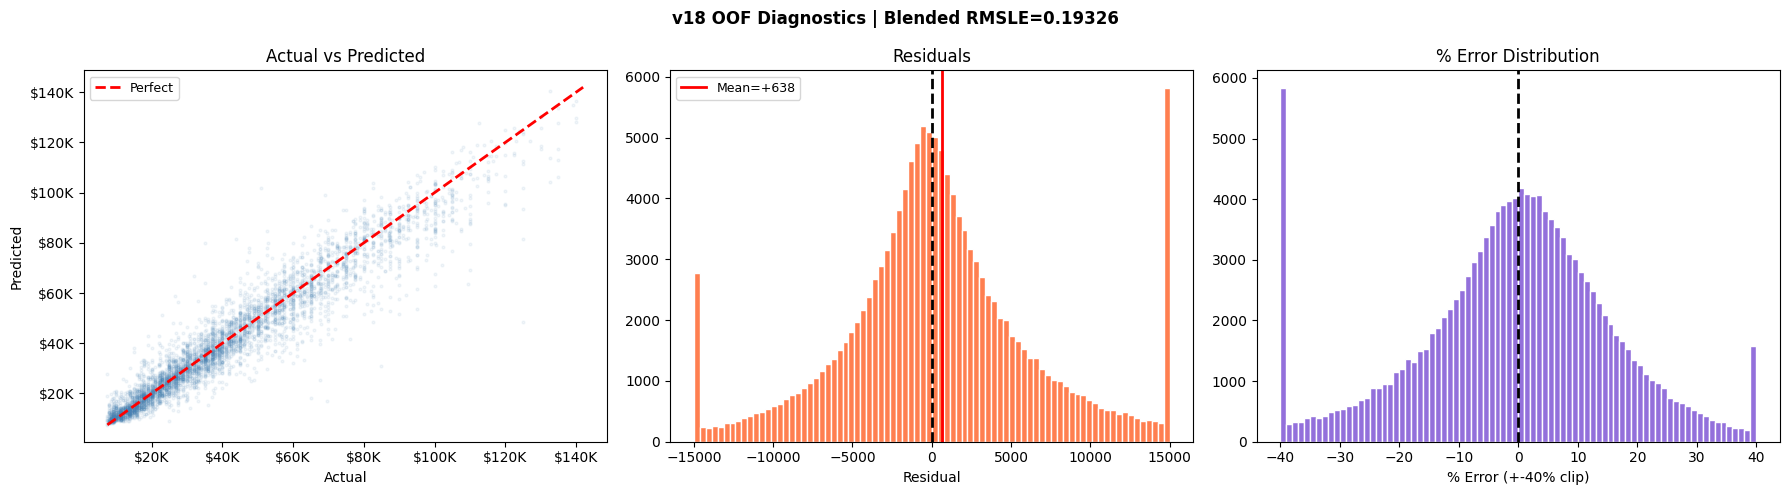

Blended OOF RMSLE : 0.19326
R2                : 0.9161
MAE               : $5,042
Median abs % err  : 9.7%

Top 40 features (LGB1 last fold):
RegionCode__x__SaleYear_TE                            116945
MachineAge_rel_ProductConfigID                         93290
InventoryGroupCategory__x__SaleYear_TE                 92179
RegionCode                                             90712
AgeBucket__x__SaleYear_TE                              87030
SaleDayOfYear_cos                                      83645
SaleDayOfYear_sin                                      82577
ProductConfigID                                        78914
SaleDayOfYear                                          78433
Spec_SubClass__x__SaleYear_TE                          76306
MachineAge_rel_Spec_BaseClass                          71187
SaleDay_sin                                            68030
FunctionalClassification__x__SaleYear_TE               67657
MachineAge_rel_RegionCode                              66060
Spec

In [ ]:
# ---------------📂 Folder 1: Predictions & Errors --------
oof_blend  = best_w[0]*oof_lgb1 + best_w[1]*oof_lgb2 + best_w[2]*oof_cat  
pred_price = np.expm1(oof_blend)
true_price = np.expm1(y_all)
residuals  = true_price - pred_price   # Residuals = actual – predicted.
pct_err    = (residuals / true_price) * 100   # Percentage error = residual relative to actual.

# ---------------📂 Folder 2: Plot Setup --------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'v18 OOF Diagnostics | Blended RMSLE={best_blend:.5f}', fontsize=12, fontweight='bold')

# ---------------📂 Folder 3: Chart 1 – Actual vs Predicted --------
idx = np.random.choice(len(true_price), min(5000, len(true_price)), replace=False)
axes[0].scatter(true_price[idx], pred_price[idx], alpha=0.07, s=4, color='steelblue')  # Randomly samples up to 5000 points, plots actual vs predicted scatter.
mn, mx = true_price.min(), true_price.max()
axes[0].plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect')   # Adds diagonal line (perfect prediction).

axes[0].set_xlabel('Actual'); axes[0].set_ylabel('Predicted'); axes[0].set_title('Actual vs Predicted')
axes[0].legend(fontsize=9)   # Labels and legend.
fmt = lambda x, _: f'${x/1000:.0f}K'    # Formats axis ticks as thousands (e.g., $50K).
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt))

# ---------------📂 Folder 4: Chart 2 – Residuals --------
axes[1].hist(residuals.clip(-15000, 15000), bins=80, color='coral', edgecolor='white')   #  Histogram of residuals, clipped to ±15,000.
axes[1].axvline(0, color='black', lw=2, ls='--')
axes[1].axvline(residuals.mean(), color='red', lw=2, label=f'Mean={residuals.mean():+,.0f}')    # Adds vertical lines: zero error and mean error.
axes[1].set_xlabel('Residual'); axes[1].set_title('Residuals'); axes[1].legend(fontsize=9)    # Labels chart.

# ---------------📂 Folder 5: Chart 3 – Percentage Error --------
axes[2].hist(pct_err.clip(-40, 40), bins=80, color='mediumpurple', edgecolor='white')   # Histogram of percentage errors, clipped to ±40%.
axes[2].axvline(0, color='black', lw=2, ls='--')
axes[2].set_xlabel('% Error (+-40% clip)'); axes[2].set_title('% Error Distribution')
plt.tight_layout()
plt.show()    # Adjusts layout, displays plots.

# ---------------📂 Folder 6: Metrics --------
print(f"Blended OOF RMSLE : {best_blend:.5f}")
print(f"R2                : {r2_score(true_price, pred_price):.4f}")
print(f"MAE               : ${np.mean(np.abs(residuals)):,.0f}")
print(f"Median abs % err  : {np.median(np.abs(pct_err)):.1f}%")

# ---------------📂 Folder 7: Feature Importance --------
fi = pd.Series(lgb1_m.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print("\nTop 40 features (LGB1 last fold):")
print(fi.head(40).to_string())
